# Churn — visualisation des données

Ce notebook explore visuellement `data/final/all_tables.csv` : 34 000 contrats, 10 colonnes.

**Objectif** : comprendre la forme des données avant de modéliser. Repérer les distributions, les valeurs extrêmes, les relations avec le churn, et les corrélations entre variables.

| Colonne | Type | Sens |
|---|---|---|
| `ANC_M` | nombre | ancienneté en mois |
| `HANDSET` | catégorie | techno du terminal (2G/3G/4G/5G) |
| `OFFRE` | catégorie | nom commercial de l'offre |
| `STATUT` | catégorie | état actuel (A actif / S suspendu) |
| `churn` | 0/1 | **le label** : 1 = part ou suspendu |
| `VOLUME_SESSION` | nombre | data moyenne par mois (Mo) |
| `MNT_RECH` | nombre | montant rechargé par mois (DT) |
| `MNT_FORFAIT` | nombre | montant en forfaits par mois (DT) |
| `APPEL_TOTAL` | nombre | **somme** des appels reçus + émis (min) |
| `SMS_TOTAL` | nombre | **somme** des SMS reçus + émis |

## 0. Préparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# style des graphiques
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'

# dossiers
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FICHIER = ROOT / 'data' / 'final' / 'all_tables.csv'

# les nombres d'abord, pour éviter les problèmes de type
NUMERIQUES = ['ANC_M', 'VOLUME_SESSION', 'MNT_RECH', 'MNT_FORFAIT',
              'APPEL_TOTAL', 'SMS_TOTAL']
CATEGORIELLES = ['HANDSET', 'OFFRE', 'STATUT']

df = pd.read_csv(FICHIER, keep_default_na=False, low_memory=False)
for c in NUMERIQUES + ['churn']:
    df[c] = pd.to_numeric(df[c], errors='coerce')

print('données chargées :', df.shape)

données chargées : (34000, 10)


## 1. Aperçu général

Avant tout graphique : combien de lignes, quels types, combien de valeurs manquantes.

In [2]:
print('=== dimensions ===')
print(f'{df.shape[0]:,} lignes x {df.shape[1]} colonnes')
print()
print('=== valeurs manquantes ===')
manquants = df.isna().sum()
for c in df.columns:
    n = int(manquants[c])
    if n:
        print(f'  {c:16s} {n:>6,}  ({n / len(df) * 100:>5.1f} %)')
print()
print('=== types ===')
print(df.dtypes.to_string())

=== dimensions ===
34,000 lignes x 10 colonnes

=== valeurs manquantes ===
  VOLUME_SESSION    9,729  ( 28.6 %)
  MNT_RECH            217  (  0.6 %)
  MNT_FORFAIT      10,628  ( 31.3 %)

=== types ===
ANC_M               int64
HANDSET            object
OFFRE              object
STATUT             object
churn               int64
VOLUME_SESSION    float64
MNT_RECH          float64
MNT_FORFAIT       float64
APPEL_TOTAL       float64
SMS_TOTAL         float64


In [3]:
df.head(10)

,ANC_M,HANDSET,OFFRE,STATUT,churn,VOLUME_SESSION,MNT_RECH,MNT_FORFAIT,APPEL_TOTAL,SMS_TOTAL
0,177,4G,PRE - TT 1500%,A,0,5277.095455,21.727273,14.281818,7359.43,1768.0
1,177,2G,PRE - Double,A,0,NaN,5.222222,0.800000,598.95,592.0
2,178,4G,PRE - TT 1500%,A,0,5242.772727,27.727273,1.737500,10223.95,2290.0
3,178,2G,PRE - Trankil TT,A,0,NaN,4.444444,NaN,758.47,687.0
4,178,2G,PRE - TT 1500%,A,0,NaN,13.636364,NaN,2479.33,837.0
5,197,4G,PRE - TT 1500%,A,0,1.275000,28.900000,NaN,9052.12,2268.0
6,177,4G,PRE - Trankil TT,A,0,366.516000,10.000000,12.000000,13440.40,1374.0
7,177,2G,PRE - TT 1500%,A,0,NaN,25.636364,0.000000,4664.93,1936.0
8,177,2G,PRE - Double,A,0,0.040000,8.272727,NaN,1032.38,781.0
9,177,5G,PRE - offre 40,A,0,384.399000,6.222222,5.400000,1447.85,1309.0


In [4]:
# statistiques descriptives
df[NUMERIQUES].describe().round(2)

,ANC_M,VOLUME_SESSION,MNT_RECH,MNT_FORFAIT,APPEL_TOTAL,SMS_TOTAL
count,34000.0,24271.00,33783.00,23372.00,34000.00,34000.00
mean,91.8,5474.00,14.19,10.23,2699.65,1246.11
std,91.7,10720.20,21.30,17.12,3929.84,1223.03
min,3.0,0.00,0.88,0.00,0.00,0.00
25%,16.0,205.47,4.91,1.85,358.37,567.00
50%,57.0,1171.74,8.33,4.98,1298.49,1010.00
75%,133.0,5306.50,17.55,13.00,3444.59,1640.00
max,311.0,194047.23,2451.50,1223.00,67259.25,49391.00


## 2. Le label : distribution du churn

Question centrale : **les classes sont-elles équilibrées ?**

Le dataset est déséquilibré (28 % de churn contre 72 %). Ce n'est pas extrême, mais ça justifie de regarder l'AUC plutôt que l'accuracy.

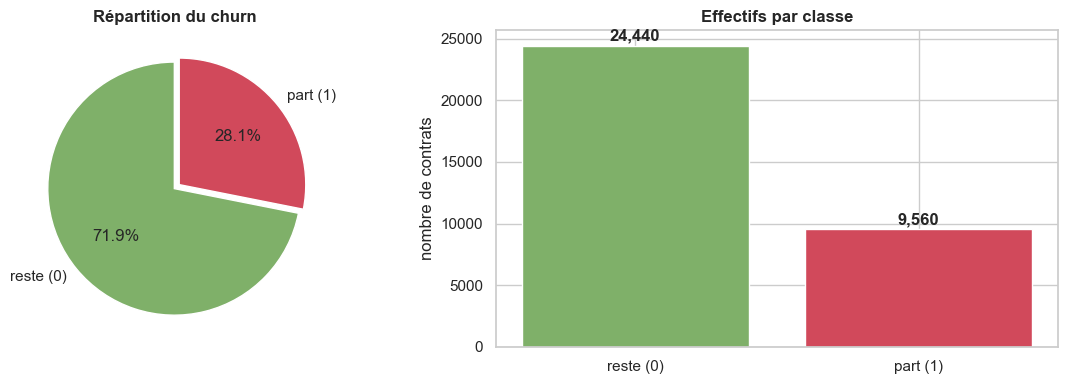

classe 0 : 24,440  (71.9 %)
classe 1 : 9,560  (28.1 %)
ratio de déséquilibre : 1 pour 2.56


In [5]:
compte = df['churn'].value_counts().sort_index()
labels = ['reste (0)', 'part (1)']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# camembert
axes[0].pie(compte, labels=labels, autopct='%1.1f%%', startangle=90,
            colors=['#7fb069', '#d1495b'], explode=(0, 0.05))
axes[0].set_title('Répartition du churn')

# barres
axes[1].bar(labels, compte.values, color=['#7fb069', '#d1495b'])
axes[1].set_ylabel('nombre de contrats')
axes[1].set_title('Effectifs par classe')
for i, v in enumerate(compte.values):
    axes[1].text(i, v + 400, f'{v:,}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

print(f'classe 0 : {compte[0]:,}  ({compte[0] / len(df) * 100:.1f} %)')
print(f'classe 1 : {compte[1]:,}  ({compte[1] / len(df) * 100:.1f} %)')
print(f'ratio de déséquilibre : 1 pour {compte[0] / compte[1]:.2f}')

## 3. Distribution des variables numériques

Toutes ces variables sont **très asymétriques** : quelques clients consomment énormément, la majorité très peu. C'est pourquoi on affiche deux échelles : normale et logarithmique.

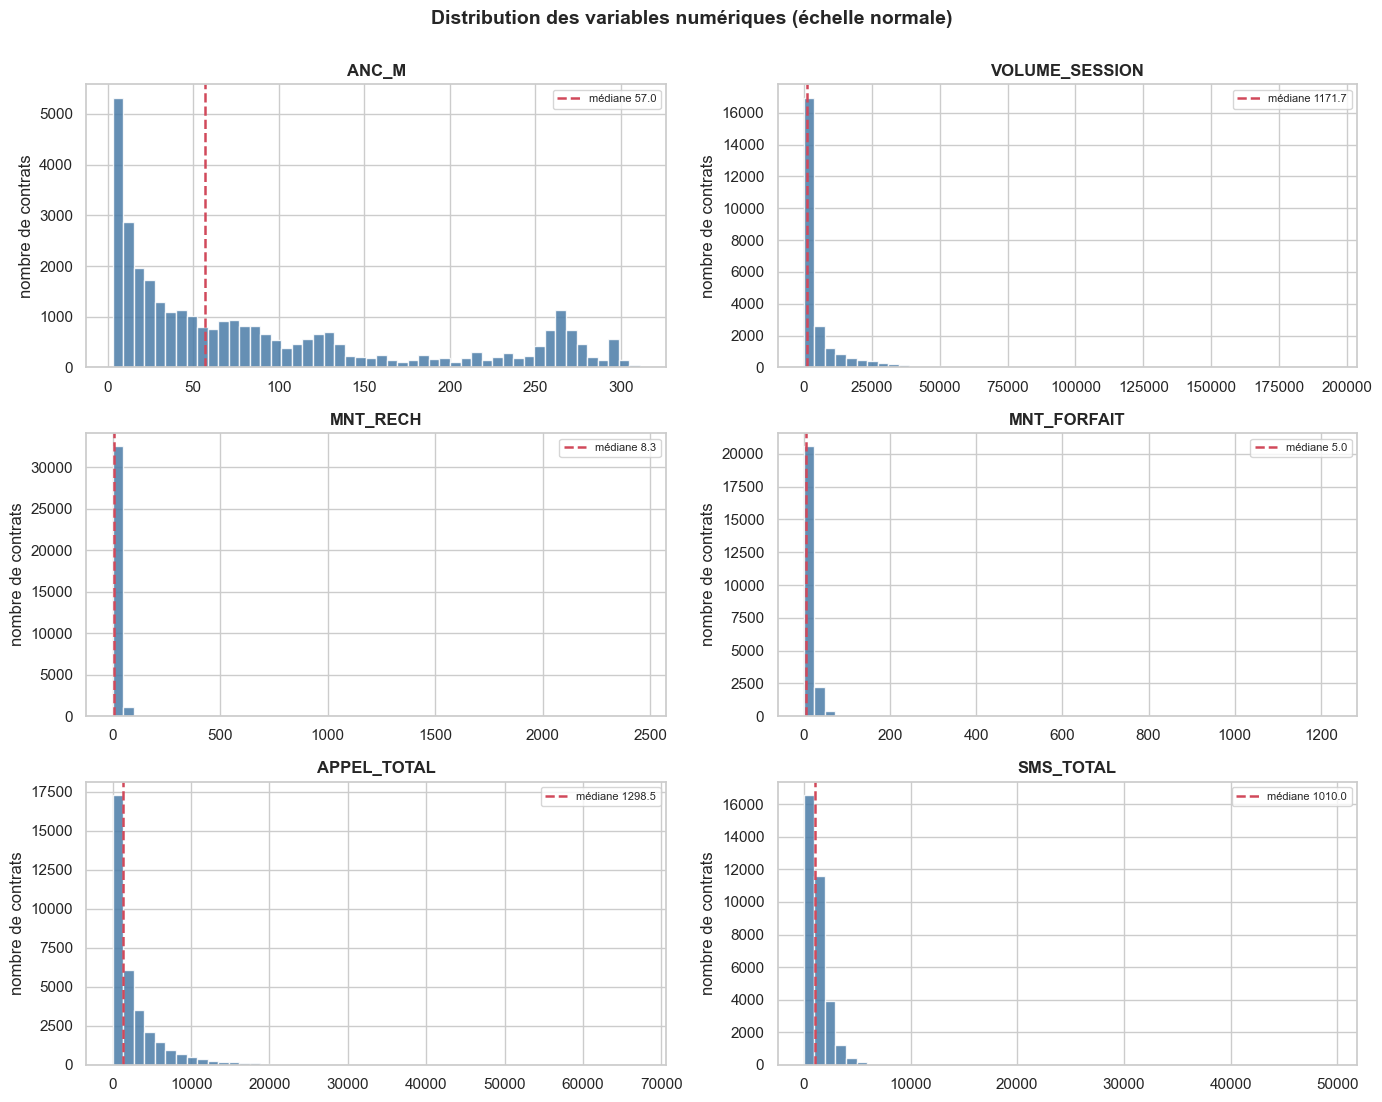

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(14, 11))
axes = axes.flatten()

for i, col in enumerate(NUMERIQUES):
    donnees = df[col].dropna()
    axes[i].hist(donnees, bins=50, color='#4a7ba7', edgecolor='white', alpha=0.85)
    axes[i].set_title(f'{col}')
    axes[i].set_ylabel('nombre de contrats')
    axes[i].axvline(donnees.median(), color='#d1495b', linestyle='--',
                    linewidth=1.8, label=f'médiane {donnees.median():.1f}')
    axes[i].legend(fontsize=8)

plt.suptitle('Distribution des variables numériques (échelle normale)',
             fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

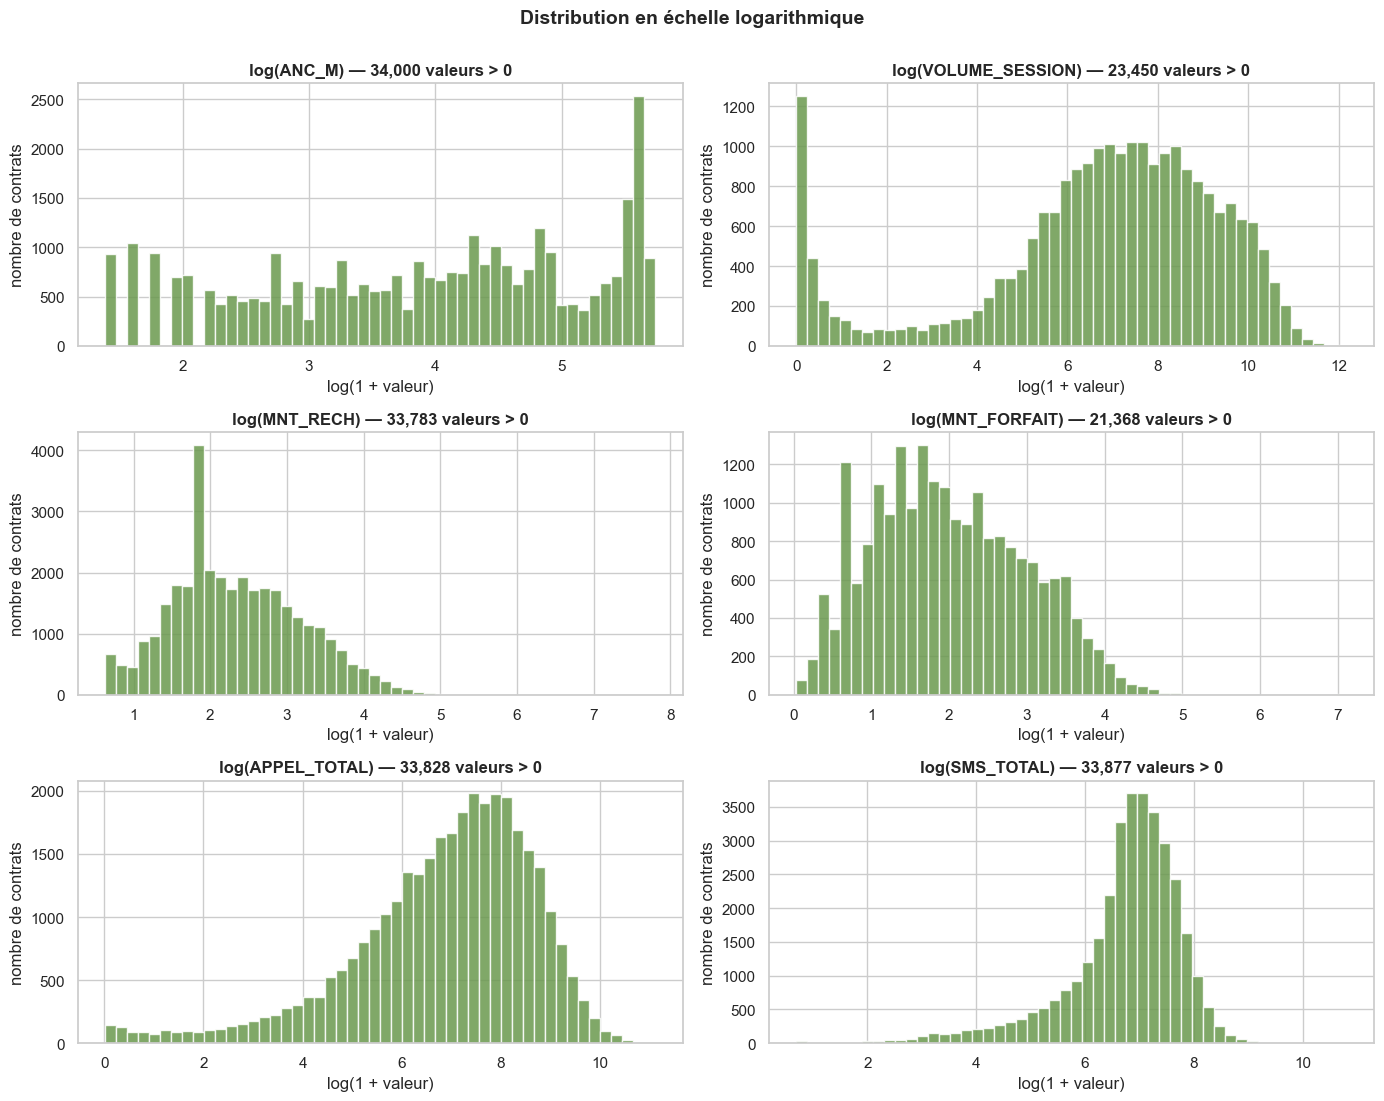

Ces variables suivent une loi à queue lourde.
Un modèle linéaire y verrait surtout les valeurs extrêmes :
le gradient boosting est plus robuste, ou on applique log1p.


In [7]:
# même chose en échelle log : les distributions redeviennent lisibles
fig, axes = plt.subplots(3, 2, figsize=(14, 11))
axes = axes.flatten()

for i, col in enumerate(NUMERIQUES):
    donnees = df[col].dropna()
    positives = donnees[donnees > 0]
    axes[i].hist(np.log1p(positives), bins=50, color='#6a994e',
                 edgecolor='white', alpha=0.85)
    axes[i].set_title(f'log({col}) — {len(positives):,} valeurs > 0')
    axes[i].set_xlabel('log(1 + valeur)')
    axes[i].set_ylabel('nombre de contrats')

plt.suptitle('Distribution en échelle logarithmique', fontsize=14,
             fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

print('Ces variables suivent une loi à queue lourde.')
print('Un modèle linéaire y verrait surtout les valeurs extrêmes :')
print('le gradient boosting est plus robuste, ou on applique log1p.')

## 4. Les valeurs numériques par classe de churn

C'est la question la plus utile : **est-ce que les partants ont un profil différent ?**

Un boxplot compare les deux groupes. Si les boîtes sont nettement décalées, la variable est informative.

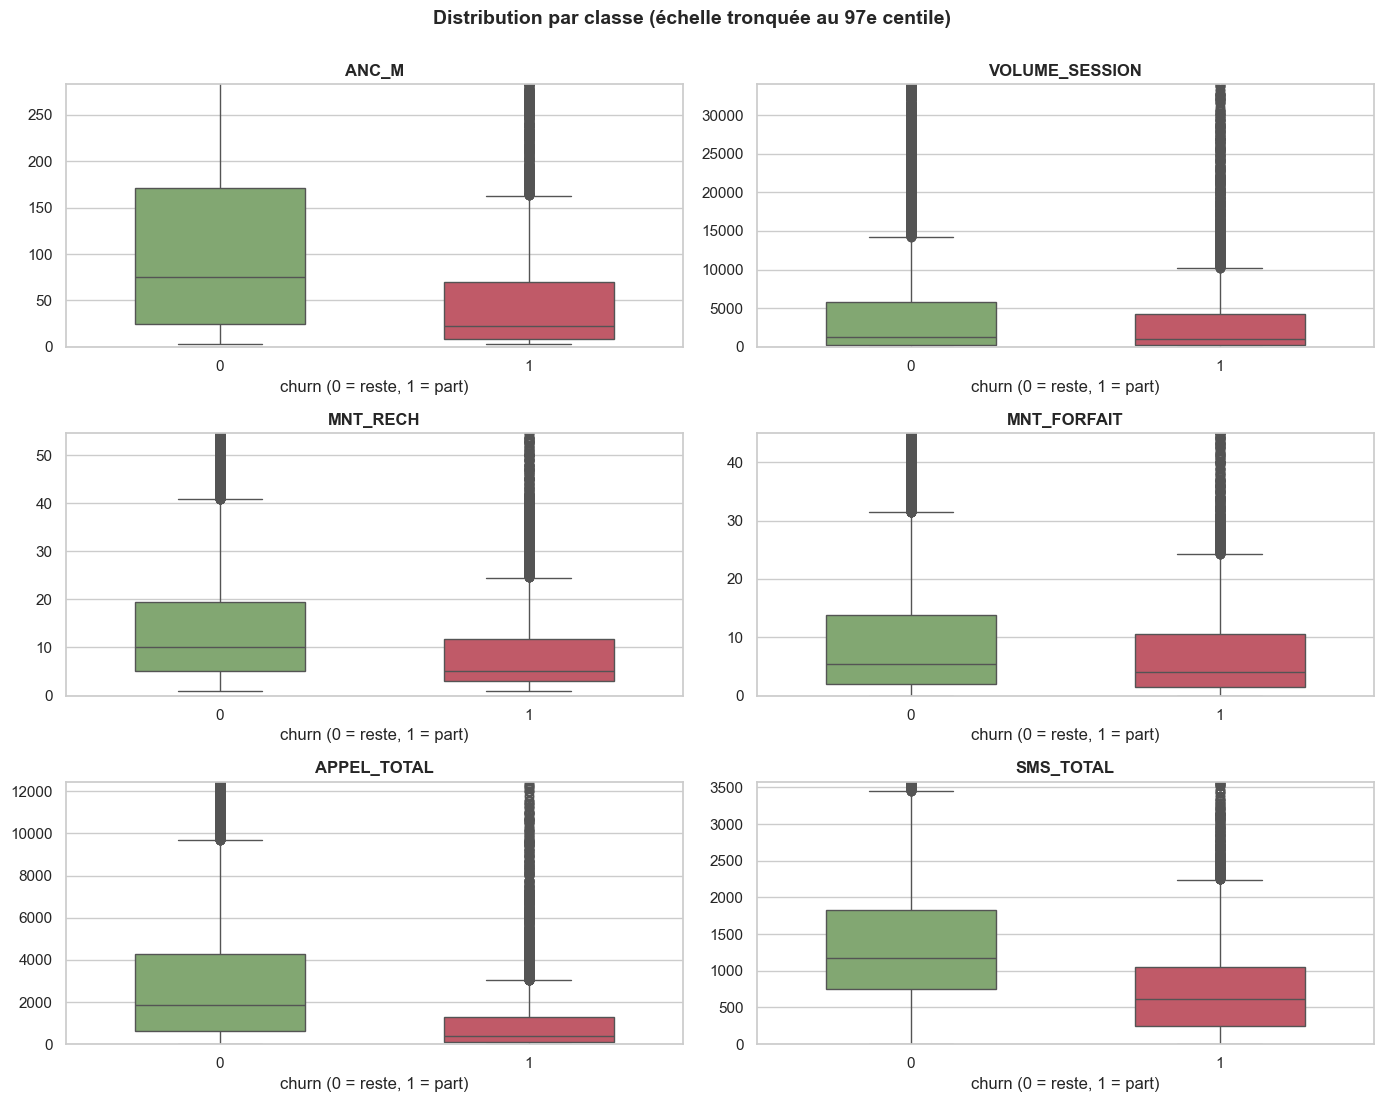

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(14, 11))
axes = axes.flatten()

for i, col in enumerate(NUMERIQUES):
    sns.boxplot(data=df, x='churn', y=col, ax=axes[i],
                hue='churn', palette=['#7fb069', '#d1495b'],
                width=0.55, legend=False)
    axes[i].set_title(col)
    axes[i].set_xlabel('churn (0 = reste, 1 = part)')
    axes[i].set_ylabel('')
    # masque les valeurs extrêmes pour voir les boîtes
    axes[i].set_ylim(0, df[col].quantile(0.97))

plt.suptitle('Distribution par classe (échelle tronquée au 97e centile)',
             fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

In [9]:
# tableau : médiane par classe
comparaison = df.groupby('churn')[NUMERIQUES].median().T
comparaison.columns = ['reste (0)', 'part (1)']
comparaison['écart %'] = ((comparaison['part (1)'] / comparaison['reste (0)'] - 1) * 100).round(1)
print('Médiane par classe :')
print(comparaison.round(2).to_string())

Médiane par classe :
                reste (0)  part (1)  écart %
ANC_M               75.00     23.00    -69.3
VOLUME_SESSION    1260.05   1009.60    -19.9
MNT_RECH            10.00      5.00    -50.0
MNT_FORFAIT          5.33      4.00    -25.0
APPEL_TOTAL       1852.96    399.07    -78.5
SMS_TOTAL         1176.00    614.00    -47.8


## 5. Variables catégorielles et churn

Pour chaque catégorie, quel est le **taux de churn** ? C'est le moyen le plus direct de voir quelles modalités sont risquées.

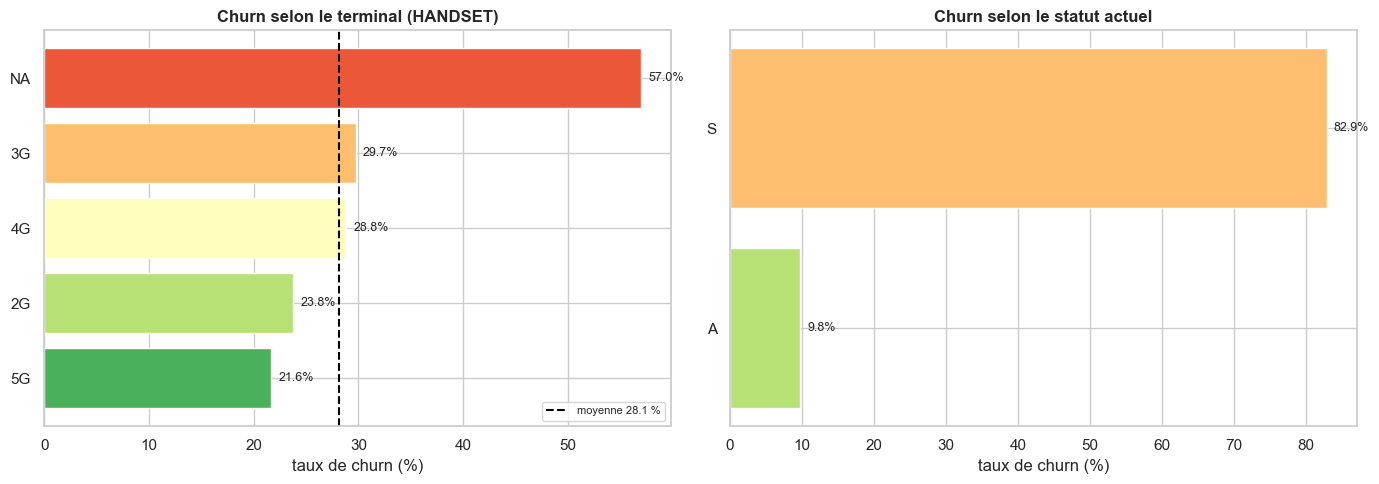

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- HANDSET ---
taux_handset = df.groupby('HANDSET')['churn'].agg(['mean', 'size']).sort_values('mean')
couleurs = sns.color_palette('RdYlGn_r', len(taux_handset))
axes[0].barh(taux_handset.index, taux_handset['mean'] * 100, color=couleurs)
axes[0].set_xlabel('taux de churn (%)')
axes[0].set_title('Churn selon le terminal (HANDSET)')
axes[0].axvline(df['churn'].mean() * 100, color='black', linestyle='--',
                linewidth=1.5, label=f'moyenne {df["churn"].mean() * 100:.1f} %')
axes[0].legend(fontsize=8)
for i, (idx, row) in enumerate(taux_handset.iterrows()):
    axes[0].text(row['mean'] * 100 + 0.7, i, f'{row["mean"] * 100:.1f}%',
                 va='center', fontsize=9)

# --- STATUT ---
taux_statut = df.groupby('STATUT')['churn'].agg(['mean', 'size']).sort_values('mean')
couleurs = sns.color_palette('RdYlGn_r', len(taux_statut))
axes[1].barh(taux_statut.index, taux_statut['mean'] * 100, color=couleurs)
axes[1].set_xlabel('taux de churn (%)')
axes[1].set_title('Churn selon le statut actuel')
for i, (idx, row) in enumerate(taux_statut.iterrows()):
    axes[1].text(row['mean'] * 100 + 1, i, f'{row["mean"] * 100:.1f}%',
                 va='center', fontsize=9)

plt.tight_layout()
plt.show()

In [11]:
# tableau détaillé
for col in ['HANDSET', 'STATUT']:
    print(f'=== {col} ===')
    t = df.groupby(col)['churn'].agg(['size', 'mean'])
    t.columns = ['contrats', 'taux_churn']
    t['taux_churn'] = (t['taux_churn'] * 100).round(1)
    print(t.sort_values('taux_churn', ascending=False).to_string())
    print()

=== HANDSET ===
         contrats  taux_churn
HANDSET                      
NA           1302        57.0
3G           1083        29.7
4G          19929        28.8
2G          10253        23.8
5G           1433        21.6

=== STATUT ===
        contrats  taux_churn
STATUT                      
S           8534        82.9
A          25466         9.8



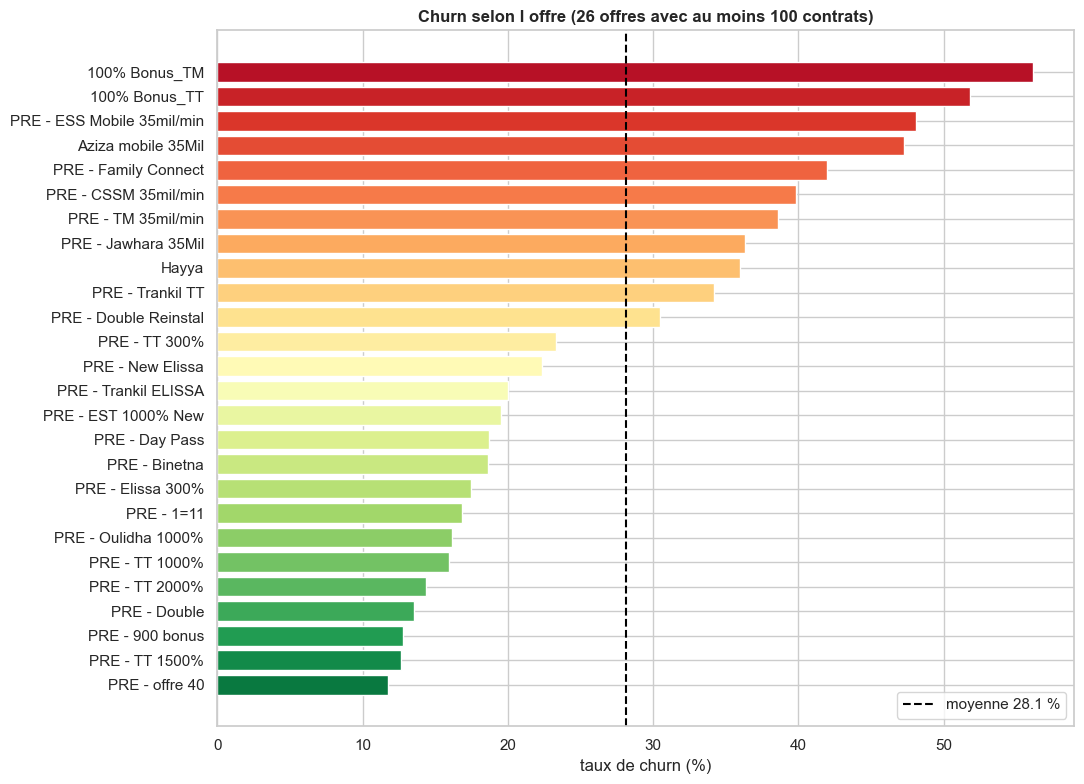

In [12]:
# --- OFFRE : 65 modalités, on garde celles avec assez de contrats ---
taux_offre = df.groupby('OFFRE')['churn'].agg(['mean', 'size'])
taux_offre = taux_offre[taux_offre['size'] >= 100].sort_values('mean')

fig, ax = plt.subplots(figsize=(11, 8))
couleurs = sns.color_palette('RdYlGn_r', len(taux_offre))
ax.barh(taux_offre.index, taux_offre['mean'] * 100, color=couleurs)
ax.set_xlabel('taux de churn (%)')
ax.set_title(f'Churn selon l offre ({len(taux_offre)} offres avec au moins 100 contrats)')
ax.axvline(df['churn'].mean() * 100, color='black', linestyle='--',
           linewidth=1.5, label=f'moyenne {df["churn"].mean() * 100:.1f} %')
ax.legend()
plt.tight_layout()
plt.show()

## 6. Corrélations entre variables

Deux informations à chercher :

- **avec le churn** : quelles variables sont liées au départ ;
- **entre elles** : quelles variables sont redondantes (à supprimer pour éviter la colinéarité).

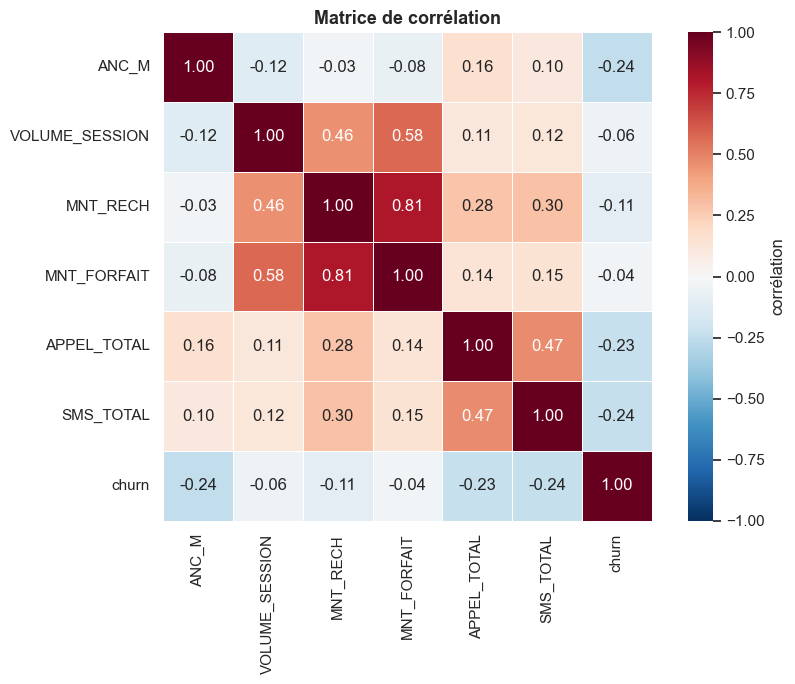

In [13]:
colonnes_num = NUMERIQUES + ['churn']
matrice = df[colonnes_num].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(matrice, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={'label': 'corrélation'})
plt.title('Matrice de corrélation', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

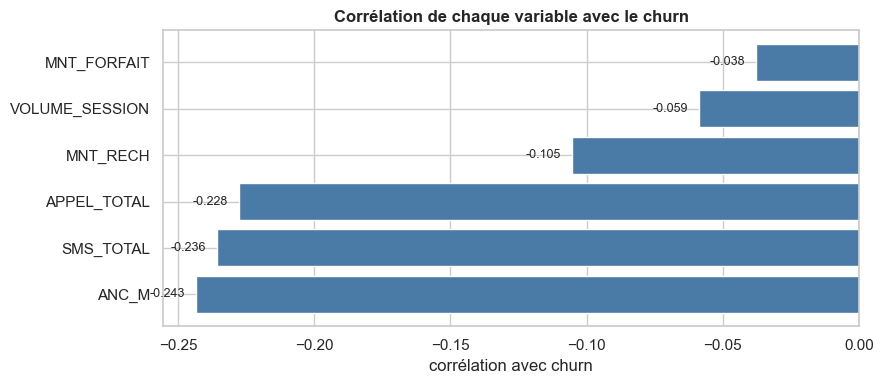

Valeurs négatives = plus la variable est haute, moins on churne.

ANC_M            -0.243
SMS_TOTAL        -0.236
APPEL_TOTAL      -0.228
MNT_RECH         -0.105
VOLUME_SESSION   -0.059
MNT_FORFAIT      -0.038


In [14]:
# corrélation avec le churn, classée
corr_churn = df[colonnes_num].corr()['churn'].drop('churn').sort_values()

plt.figure(figsize=(9, 4))
couleurs = ['#d1495b' if v > 0 else '#4a7ba7' for v in corr_churn]
plt.barh(corr_churn.index, corr_churn.values, color=couleurs)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('corrélation avec churn')
plt.title('Corrélation de chaque variable avec le churn')
for i, v in enumerate(corr_churn.values):
    plt.text(v + (0.004 if v >= 0 else -0.004), i, f'{v:.3f}',
             va='center', ha='left' if v >= 0 else 'right', fontsize=9)
plt.tight_layout()
plt.show()

print('Valeurs négatives = plus la variable est haute, moins on churne.')
print()
print(corr_churn.round(3).to_string())

### Corrélations entre variables : où sont les redondances ?

Une corrélation au-dessus de 0,8 entre deux variables signifie qu'elles portent presque la même information.

In [15]:
# paires fortement corrélées
paires = []
for i, a in enumerate(NUMERIQUES):
    for b in NUMERIQUES[i + 1:]:
        r = df[a].corr(df[b])
        if abs(r) > 0.5:
            paires.append((a, b, r))

if paires:
    print('Paires corrélées à plus de 0,5 :')
    for a, b, r in sorted(paires, key=lambda x: -abs(x[2])):
        print(f'  {a:16s} / {b:16s}  r = {r:+.3f}')
else:
    print('Aucune paire au-dessus de 0,5 : pas de redondance forte.')

Paires corrélées à plus de 0,5 :
  MNT_RECH         / MNT_FORFAIT       r = +0.806
  VOLUME_SESSION   / MNT_FORFAIT       r = +0.577


## 7. Relations entre variables et churn en 2D

Les corrélations ne montrent que les relations linéaires. Ce graphique croise deux variables clés et colore par churn.

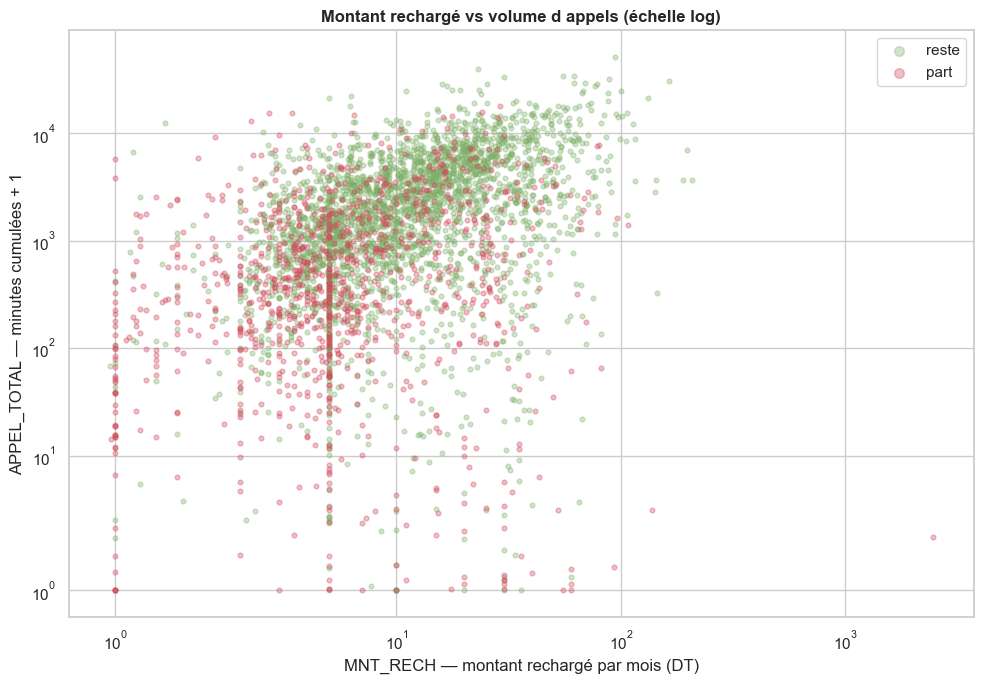

Les partants (rouge) se concentrent en bas à gauche :
peu de recharge ET peu d appels.


In [16]:
# échantillon pour ne pas surcharger le graphique
echantillon = df.sample(4000, random_state=42)

fig, ax = plt.subplots(figsize=(10, 7))
for classe, couleur, nom in [(0, '#7fb069', 'reste'), (1, '#d1495b', 'part')]:
    sous = echantillon[echantillon['churn'] == classe]
    ax.scatter(sous['MNT_RECH'], sous['APPEL_TOTAL'] + 1,
               alpha=0.35, s=12, c=couleur, label=nom)

ax.set_xscale('symlog')
ax.set_yscale('symlog')
ax.set_xlabel('MNT_RECH — montant rechargé par mois (DT)')
ax.set_ylabel('APPEL_TOTAL — minutes cumulées + 1')
ax.set_title('Montant rechargé vs volume d appels (échelle log)')
ax.legend(markerscale=2)
plt.tight_layout()
plt.show()

print('Les partants (rouge) se concentrent en bas à gauche :')
print('peu de recharge ET peu d appels.')

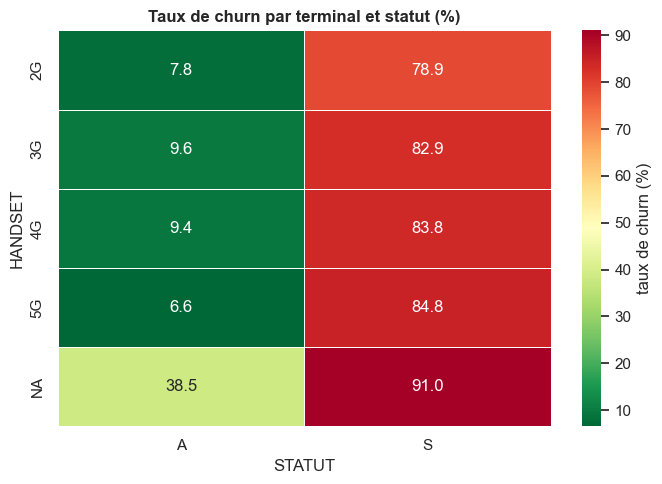

In [17]:
# churn croisé sur deux variables catégorielles
pivot = df.pivot_table(index='HANDSET', columns='STATUT',
                       values='churn', aggfunc='mean') * 100

plt.figure(figsize=(7, 5))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='RdYlGn_r',
            cbar_kws={'label': 'taux de churn (%)'}, linewidths=0.5)
plt.title('Taux de churn par terminal et statut (%)')
plt.tight_layout()
plt.show()

## 8. Le rôle de l'ancienneté

`ANC_M` est souvent la variable la plus forte en télécom : les clients récents partent beaucoup plus.

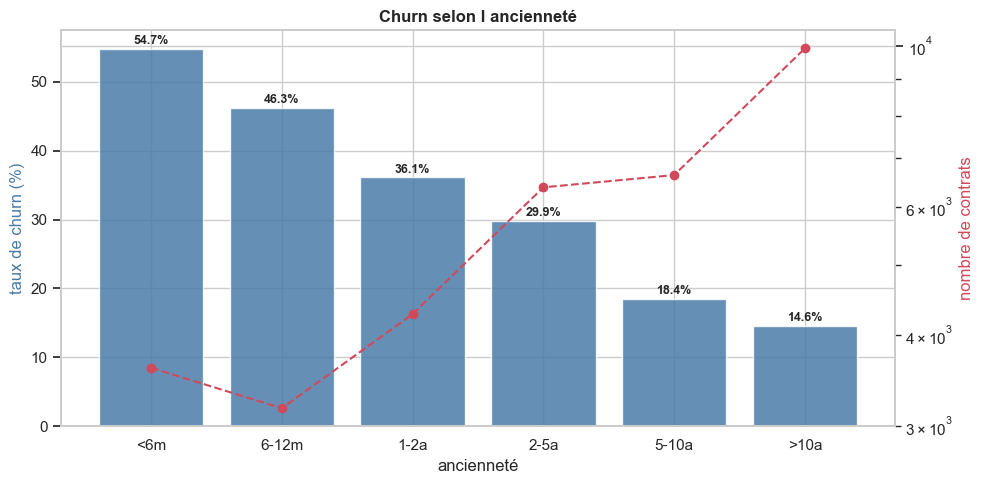

             taux_churn  contrats
tranche_anc                      
<6m               0.547      3605
6-12m             0.463      3171
1-2a              0.361      4274
2-5a              0.299      6387
5-10a             0.184      6640
>10a              0.146      9923


In [18]:
# churn par tranche d'ancienneté
df['tranche_anc'] = pd.cut(df['ANC_M'],
                           bins=[0, 6, 12, 24, 60, 120, 1000],
                           labels=['<6m', '6-12m', '1-2a', '2-5a', '5-10a', '>10a'])

taux = df.groupby('tranche_anc', observed=False)['churn'].agg(['mean', 'size'])

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(taux.index.astype(str), taux['mean'] * 100, color='#4a7ba7', alpha=0.85)
ax1.set_ylabel('taux de churn (%)', color='#4a7ba7')
ax1.set_xlabel('ancienneté')
ax1.set_title('Churn selon l ancienneté')
for i, v in enumerate(taux['mean'] * 100):
    ax1.text(i, v + 0.7, f'{v:.1f}%', ha='center', fontweight='bold', fontsize=9)

# effectifs sur un second axe
ax2 = ax1.twinx()
ax2.plot(taux.index.astype(str), taux['size'], 'o--', color='#d1495b', linewidth=1.5)
ax2.set_ylabel('nombre de contrats', color='#d1495b')
ax2.set_yscale('log')

plt.tight_layout()
plt.show()

print(taux.rename(columns={'mean': 'taux_churn', 'size': 'contrats'}).round(3).to_string())

## 9. Synthèse des observations

Ce que les graphiques révèlent, à retenir pour la modélisation.

In [19]:
resume = pd.DataFrame({
    'variable': NUMERIQUES,
    'manquants_%': [round(df[c].isna().mean() * 100, 1) for c in NUMERIQUES],
    'mediane': [round(df[c].median(), 1) if df[c].notna().any() else 0 for c in NUMERIQUES],
    'max': [round(df[c].max(), 1) if df[c].notna().any() else 0 for c in NUMERIQUES],
    'corr_churn': [round(df[c].corr(df['churn']), 3) for c in NUMERIQUES],
})
print(resume.to_string(index=False))

      variable  manquants_%  mediane      max  corr_churn
         ANC_M          0.0     57.0    311.0      -0.243
VOLUME_SESSION         28.6   1171.7 194047.2      -0.059
      MNT_RECH          0.6      8.3   2451.5      -0.105
   MNT_FORFAIT         31.3      5.0   1223.0      -0.038
   APPEL_TOTAL          0.0   1298.5  67259.2      -0.228
     SMS_TOTAL          0.0   1010.0  49391.0      -0.236


### Les points importants

**1. Classes déséquilibrées (28 % / 72 %)**
Ce n'est pas extrême. Une précision brute serait trompeuse (un modèle qui prédit toujours 0 aurait 72 % d'accuracy) : on évalue avec l'**AUC**, voire le rappel sur la classe 1.

**2. Distributions à queue lourde**
`VOLUME_SESSION`, `MNT_RECH`, `APPEL_TOTAL`, `SMS_TOTAL` vont de 0 à plusieurs milliers. Un `log1p` aide les modèles linéaires ; le gradient boosting s'en passe.

**3. Valeurs manquantes = inactivité**
28,6 % n'ont pas de `VOLUME_SESSION`, 31,3 % pas de `MNT_FORFAIT`. Ce n'est pas un défaut de collecte : ces clients n'ont simplement rien consommé. Le vide est un signal, pas un trou.

**4. `STATUT` est de loin la variable la plus liée au churn**
Un client `S` (suspendu) part dans plus de 80 % des cas. Ça écrase les autres variables dans un modèle — c'est un choix à assumer (voir la section 6 du notebook précédent).

**5. L'ancienneté compte, mais pas linéairement**
Le churn baisse avec l'ancienneté, puis se stabilise. Découper en tranches est plus informatif qu'une valeur brute.

**6. Redondances**
Les corrélations entre variables restent modérées (< 0,5), sauf cas particuliers. Pas de colinéarité majeure à traiter.